In [1]:
!pip install ultralytics supervision

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.9/79.9 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 280.2/280.2 kB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 12.4 MB/s eta 0:00:00


Helper Function to draw trajectory

In [30]:
import cv2

def draw_trajectory(frame, track):

    points = track.centers()

    if len(points) < 2:
        return

    for i in range(1, len(points)):

        p1 = tuple(map(int, points[i - 1]))
        p2 = tuple(map(int, points[i]))

        cv2.line(frame, p1, p2, (0,255,0), 2)

In [31]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

results = model.track(
    source="/content/cam_video.mp4",
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    verbose=False
)

In [32]:
class_names = model.names

## Track Class For representing every tracked object

In [33]:
# Track Class Definition

from collections import deque
import math

class Track:

    def __init__(self, track_id, class_name):
        self.id = track_id
        self.class_name = class_name

        self.history= deque(maxlen=30)
        self.last_seen = -1
        self.age = 0

    @property
    def current(self):
        if not self.history:
            return None
        return self.history[-1]

    @property
    def center(self):
        if not self.history:
            return None
        return self.history[-1].center

    def speed(self, window=5):
        vx, vy = self.velocity(window)

        return math.hypot(vx, vy)

    def velocity(self, window=5):
        if len(self.history) < window:
            return (0.0, 0.0)

        x1, y1 = self.history[-window].center
        x2, y2 = self.history[-1].center

        dt = window - 1

        vx = (x2 - x1) / dt
        vy = (y2 - y1) / dt

        return (vx, vy)

    def centers(self):
        return [obs.center for obs in self.history]

    def path_length(self):

        points = self.centers()

        if len(points) < 2:
            return 0

        distance = 0

        for i in range(1, len(points)):

            x1, y1 = points[i-1]
            x2, y2 = points[i]

            distance += math.hypot(x2-x1, y2-y1)

        return distance

    def update(self, observation):
        self.last_seen = observation.frame
        self.age += 1
        self.history.append(observation)


## Observation class to store history of observations

In [34]:
from dataclasses import dataclass

@dataclass
class Observation:
    frame: int
    bbox: tuple
    center: tuple
    confidence: float

    @property
    def width(self):
        x1, _, x2, _ = self.bbox
        return x2 - x1

    @property
    def height(self):
        _, y1, _, y2 = self.bbox
        return y2 - y1

    @property
    def area(self):
        return self.width * self.height

    @property
    def area(self):
        return self.width * self.height

    @property
    def bottom_center(self):
        x1, y1, x2, y2 = self.bbox
        return ((x1 + x2) / 2, y2)

# Start

In [35]:
from collections import defaultdict

tracks = defaultdict(lambda: Track(None, None))

In [36]:
for frame_idx, result in enumerate(results):
    if frame_idx > 100:
        break
    for box in result.boxes:

        track_id = int(box.id.item()) if box.id is not None else None

        class_id = int(box.cls.item())
        class_name = class_names[class_id]

        confidence = float(box.conf.item())

        x1, y1, x2, y2 = box.xyxy[0].tolist()

        x_center = (x1 + x2) / 2
        y_center = (y1 + y2) / 2

        observation = Observation(
            frame = frame_idx,
            bbox = (x1, y1, x2, y2),
            center = (x_center, y_center),
            confidence = confidence
        )

        # Initialize track details if it's a new track
        if track_id not in tracks:
            tracks[track_id] = Track(track_id, class_name)

        # Update last_seen and append observation to history
        track = tracks[track_id]
        track.update(observation)


In [37]:
# Testing

annotated = result.plot()

for track in tracks.values():
    vx, vy = track.velocity()

    print(
        track.id,
        track.class_name,
        f"vx={vx:.2f}",
        f"vy={vy:.2f}",
        f"speed={track.speed():.2f}"
    )
    draw_trajectory(annotated, track)

1 person vx=-0.14 vy=0.22 speed=0.26
2 person vx=-0.13 vy=-0.16 speed=0.21
3 person vx=-0.46 vy=-0.37 speed=0.59
7 person vx=1.44 vy=2.18 speed=2.61
15 boat vx=0.09 vy=1.05 speed=1.05
34 person vx=0.31 vy=-0.74 speed=0.80
39 bicycle vx=0.00 vy=0.00 speed=0.00


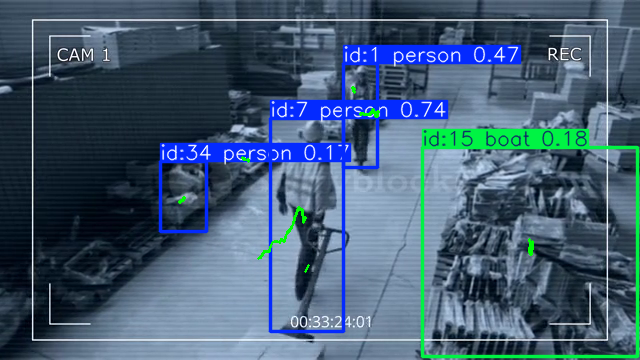

In [38]:
from google.colab.patches import cv2_imshow

cv2_imshow(annotated)